In [1]:
import os
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf

In [2]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

countries = country_weights_dict['countries_gdf']
eu_mode = 'aggregated'

## One-at-a-time sensitivity testing across 5 parameters

Test sensitivity to `buffer_months`, `tau`, `eval_months`, `k_setting`, and `injection_type` **one parameter at a time**: every scenario below changes exactly one parameter away from the default, holding the rest fixed. 

**Default parameter settings** (baseline every comparison is made against):
- `buffer_months = 12`
- `tau = 12`
- `eval_months = 36`
- `k_setting = country_k_2035`
- `injection_type = single_lat` ("single latitude")

**Alternate levels tested** (each swapped in one at a time, others held at default):
- `buffer_months`: 6, 18
- `tau`: 6, 18
- `eval_months`: 24, 48
- `k_setting`: `country_k_2050` (country-specific k, 2050 version)
- `injection_type`: `uniform` ("global uniform")


In [6]:
## Default parameter settings
default_params = dict(injection_type="single_lat",
                      k_setting="country_k_2035",
                      buffer=12, tau=12, eval_len=36)

## Alternate values to test for each parameter
param_test_levels = {"buffer": [6, 18], "tau": [6, 18],
                    "eval_len": [24, 48], "k_setting": ["country_k_2050"],
                    "injection_type": ["uniform"]}

## Map short k_setting names -> the string used in saved filenames
k_setting_file_suffix = {"country_k_2035": "country_k_2035",
                         "country_k_2050": "country_k_2050"}

## Map short k_setting names -> suffix appended to the results directory name
## (results_buffer=12m_tau=12m_eval=36m + suffix + /)
k_setting_dir_suffix = {"country_k_2035": "", "country_k_2050": "_k_2050"}

## Map short injection_type names -> the filename prefix used when the min-injection-rate
## datasets were saved (05_find_min_injection_rate_..._.py)
injection_type_file_prefix = {"single_lat": "single_lat",
                              "uniform": "global_uniform"}

## Human-readable labels for every parameter level, used in plot legends below
label_lookup = {"single_lat": "Single latitude injection",
                "uniform": "Global uniform injection",
                "country_k_2035": "Country-specific k (2035)",
                "country_k_2050": "Country-specific k (2050)"}

## Generic loader: fetch the min-injection-rate dataset for one full parameter combination

Given a full set of `(injection_type, k_setting, buffer_months, tau, eval_months)`, this loads the matching `.nc` file, and applies `select_eu_mode`. Returns `None` if that combination hasn't been run yet

In [7]:
def load_min_injection_dataset(injection_type, k_setting, buffer, tau, eval_len):
    """
    Load + EU-fold the min_injection_rate Dataset for one full parameter combination.
    Returns None (and prints a note) if the corresponding results file doesn't exist yet.
    """
    rpath = newpath + f'results_buffer={buffer}m_tau={tau}m_eval={eval_len}m{k_setting_dir_suffix[k_setting]}/'
    
    fname = f'{injection_type_file_prefix[injection_type]}_min_rates' + \
            f'_{k_setting_file_suffix[k_setting]}_EU_agg_nans_replaced.nc'
    
    fpath = rpath + fname

    if not os.path.exists(fpath):
        print(f"  missing file: {fpath}")
        return None

    ds = xr.open_dataset(fpath)
    ds = select_eu_mode(ds, eu_mode)
    return ds

## Build the one-at-a-time scenario list

One shared default scenario, plus one scenario per alternate level of each parameter (with every other parameter held at `default_params`). Each scenario keeps the raw `(country, ensemble)` `min_injection_rate` DataArray for the reductions below.


In [19]:
scenarios = []

def add_scenario(params, param_varied, level, is_default=False):
    """Load data for `params` and append a scenario dict; returns the scenario (or None if missing)."""
    ds = load_min_injection_dataset(**params)
    if ds is None:
        return None
    s = dict(param_varied=param_varied, level=level, is_default=is_default,
             data=ds["min_injection_rate"], **params)
    scenarios.append(s)
    return s

## Default scenario (shared baseline for every parameter's comparison)
default_scenario = add_scenario(default_params, param_varied="default", level=None, is_default=True)
assert default_scenario is not None, \
    "Default scenario data not found -- check default_params / file paths / k_setting_file_suffix mapping"

## One-at-a-time alternates: swap in each level of each parameter, others stay at default
for param, levels in param_test_levels.items():
    for level in levels:
        params = {**default_params, param: level}
        add_scenario(params, param_varied=param, level=level)

print(f"\n{len(scenarios)} scenarios loaded (including default)")


9 scenarios loaded (including default)


In [20]:
expected = 1 + sum(len(levels) for levels in param_test_levels.values())  # 11 with current config
assert len(scenarios) == expected, (
    f"Expected {expected} RC'14 scenarios but only {len(scenarios)} loaded")

## 90th percentile min injection rate by country, per scenario

For each scenario, take the 90th percentile of `min_injection_rate` across ensemble members, keeping `country` as a dimension. This gives the (90%-of-ensemble) minimum injection amount for each country individually 

In [21]:
countries_of_interest = list(default_scenario['data'].country.values) ## All countries

country_short_names = {'Australia':'Australia',
                       'Bangladesh':'Bangladesh',
                       'Brazil':'Brazil',
                       'China':'China',
                       'Egypt':'Egypt',
                       'Ethiopia':'Ethiopia',
                       'European Union':'EU',
                       'India':'India',
                       'Indonesia':'Indonesia',
                       'Japan':'Japan',
                       'Nigeria':'Nigeria',
                       'Pakistan':'Pakistan',
                       'Russia':'Russia',
                       'Saudi Arabia':'Saudi Arabia',
                       'South Africa':'South Africa',
                       'United Kingdom':'UK',
                       'United States of America':'USA'}

for s in scenarios:
    da = s["data"]  # dims: (country, ensemble)
    p90_by_country = da.quantile(0.90, dim="ensemble")  # dims: (country,)
    s["p90_by_country"] = p90_by_country.sel(country=countries_of_interest)

## Assemble a long-format DataFrame for plotting

One row per (scenario, country), with the scenario's varied parameter/level and its 90th-percentile min injection rate for that country.


In [22]:
def scenario_label(s):
    if s["is_default"]:
        return (f"Default (buffer=12, tau=12, eval_len=36m)")
    
    level_label = label_lookup.get(s["level"], s["level"])
    param_display = {"buffer": "buffer",
                     "tau": "tau",
                     "eval_len": "eval_len",
                     "k_setting": "k_setting",
                     "injection_type": "injection_type"}[s["param_varied"]]
    
    if s["param_varied"] in ("buffer", "tau", "eval_len"):
        return f"{param_display} = {s['level']}m"
    return f"{param_display} = {level_label}"

records = []
for s in scenarios:
    label = scenario_label(s)
    for country in countries_of_interest:
        val = float(s["p90_by_country"].sel(country=country).values)
        records.append(dict(
            scenario=label,
            param_varied=s["param_varied"],
            level=s["level"],
            country=country,
            country_label=country_short_names[country],
            p90_min_injection=val))

df = pd.DataFrame(records)
df

,scenario,param_varied,level,country,country_label,p90_min_injection
0,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Australia,Australia,10.0
1,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Bangladesh,Bangladesh,10.0
2,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Brazil,Brazil,15.0
3,"Default (buffer=12, tau=12, eval_len=36m)",default,None,China,China,5.0
4,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Egypt,Egypt,6.0
...,...,...,...,...,...,...
148,injection_type = Global uniform injection,injection_type,uniform,Russia,Russia,16.0
149,injection_type = Global uniform injection,injection_type,uniform,Saudi Arabia,Saudi Arabia,11.0
150,injection_type = Global uniform injection,injection_type,uniform,South Africa,South Africa,19.0
151,injection_type = Global uniform injection,injection_type,uniform,United Kingdom,UK,23.0


## Plot: 90th-percentile min injection rate by country, across one-at-a-time scenarios

Y-axis: deploying country (subset). X-axis: 90th-percentile min injection rate (Tg/yr) across ensemble members. Each scenario (default + one changed parameter) gets its own marker shape, colored by which parameter was varied, so you can see -- for each country -- how much the required injection rate shifts as each parameter is perturbed away from default.


In [23]:
## "Simple memory model" results
spath = newpath + 'simple_memory_model/'

In [24]:
# model_type = 'moving_baseline'   # 'moving_baseline' or 'stationary_baseline'
model_type = 'stationary_baseline'
print(model_type)
################

if model_type == 'moving_baseline':
    b12_t2 = xr.open_dataset(spath + '12m_buffer_2_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')
    b12_t3 = xr.open_dataset(spath + '12m_buffer_3_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')
    b12_t4 = xr.open_dataset(spath + '12m_buffer_4_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')
    b18_t3 = xr.open_dataset(spath + 'buffer=18m_3_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')
    b6_t3  = xr.open_dataset(spath + 'buffer=6m_3_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')

elif model_type == 'stationary_baseline':
    b12_t2 = xr.open_dataset(spath + '12m_buffer_2_test_years_0.9_cooler_all_countries.nc')
    b12_t3 = xr.open_dataset(spath + '12m_buffer_3_test_years_0.9_cooler_all_countries.nc')
    b12_t4 = xr.open_dataset(spath + '12m_buffer_4_test_years_0.9_cooler_all_countries.nc')
    b18_t3 = xr.open_dataset(spath + 'buffer=18m_3_test_years_0.9_cooler_all_countries.nc')
    b6_t3  = xr.open_dataset(spath + 'buffer=6m_3_test_years_0.9_cooler_all_countries.nc')

else:
    raise ValueError(f"Unrecognized model_type: {model_type!r} "
                      "(expected 'moving_baseline' or 'stationary_baseline')")

## load the moving-baseline version of the buffer=12m, eval=3yr file (independent of
## model_type above), so it can be added as an extra "moving baseline" scenario for the simple
## memory model.
b12_t3_moving = xr.open_dataset(spath + '12m_buffer_3_test_years_0.9_cooler_MOVING_BASELINE_YEAR_BY_YEAR_all_countries.nc')

## 2050-deployment version of the default (buffer=12m, eval=3yr) M et al. '19 file. 
if model_type == 'moving_baseline':
    b12_t3_2050 = xr.open_dataset(spath + '2050/' + \
                    'buffer=12m_3_test_years_moving_baseline_2050.nc')
else:
    b12_t3_2050 = xr.open_dataset(spath + '2050/' + \
                     'buffer=12m_3_test_years_2050.nc')


stationary_baseline


In [25]:
## ------------------------------------------------------------------
## Simple memory model ("M et al. '19"): build a scenario list + long-format
## DataFrame, parallel to the RC'14 `scenarios` / `df` built above.
##
## This model has no tau / k_setting parameters 
## ------------------------------------------------------------------

def mem_scenario_label(param_varied, level, is_default=False):
    if is_default:
        return "M et al. '19 Default"
    if param_varied == "buffer":
        return f"M et al. '19 buffer = {level}m"
    if param_varied == "eval_len":
        return f"M et al. '19 eval_len = {level}m"
    if param_varied == "moving_baseline":
        return "M et al. '19 moving baseline"
    if param_varied == "deployment":
        return f"M et al. '19 deployment = {level}"
    return f"M et al. '19 injection_type = {level}"

## b12_t3 (buffer=12m, eval=3yr) is the shared default file for all three sweeps.
mem_scenario_specs = [
    (True,  "default",         None,      "single_lat", b12_t3),
    (False, "buffer",          6,         "single_lat", b6_t3),
    (False, "buffer",          18,        "single_lat", b18_t3),
    (False, "eval_len",        24,        "single_lat", b12_t2),
    (False, "eval_len",        48,        "single_lat", b12_t4),
    (False, "injection_type",  "uniform", "uniform",    b12_t3),
    (False, "moving_baseline", None,      "single_lat", b12_t3_moving),
    (False, "deployment",      2050,      "single_lat", b12_t3_2050)]

mem_records = []
for is_default, param_varied, level, inj_type, ds in mem_scenario_specs:
    label = mem_scenario_label(param_varied, level, is_default=is_default)
    da = ds["min_injection_rate"].sel(injection_type=inj_type)
    
    for country in countries_of_interest:
        mem_records.append(dict(
            scenario=label,
            param_varied=param_varied if not is_default else "default",
            level=level,
            country=country,
            country_label=country_short_names[country],
            min_injection_rate=float(da.sel(country=country).values)))
        
assert len(mem_records) == len(mem_scenario_specs) * len(countries_of_interest), \
    "Not every M et al. '19 scenario/country combination produced a record. check for missing data."

df_mem = pd.DataFrame(mem_records)
df_mem

,scenario,param_varied,level,country,country_label,min_injection_rate
0,M et al. '19 Default,default,None,Australia,Australia,8.0
1,M et al. '19 Default,default,None,Bangladesh,Bangladesh,8.0
2,M et al. '19 Default,default,None,Brazil,Brazil,14.0
3,M et al. '19 Default,default,None,China,China,5.0
4,M et al. '19 Default,default,None,Egypt,Egypt,5.0
...,...,...,...,...,...,...
131,M et al. '19 deployment = 2050,deployment,2050,Russia,Russia,11.0
132,M et al. '19 deployment = 2050,deployment,2050,Saudi Arabia,Saudi Arabia,5.0
133,M et al. '19 deployment = 2050,deployment,2050,South Africa,South Africa,10.0
134,M et al. '19 deployment = 2050,deployment,2050,United Kingdom,UK,12.0


## RC'14 vs. M et al. '19, side by side per country

Deploying countries ordered left-to-right by CIDER injection latitude. Each country gets 2 columns: the RC'14 model scenarios (filled markers, left column) and the M et al. '19 simple memory model scenarios (open markers, right column). Marker shape is shared across the two models wherever the parameter/level matches (e.g. `buffer = 6m` is a square in both).


In [26]:
cider_inj_lats_popweighted = xr.open_dataset(basepath + \
                                'cider_injection_latitudes_by_country_popweighted.nc')
for country in cider_inj_lats_popweighted.country.values:

    print(country, cider_inj_lats_popweighted.sel(country=country).nearest_cider_lat.values)

Antarctica -60.0
United Kingdom 60.0
New Zealand -30.0
Chile -30.0
Australia -30.0
Argentina -30.0
South Africa -30.0
France 30.0
Uruguay -30.0
Brazil -15.0
Namibia -15.0
Madagascar -15.0
Tonga -15.0
Mauritius -15.0
Lesotho -30.0
Mozambique -15.0
Fiji -15.0
Paraguay -30.0
eSwatini -30.0
Botswana -15.0
Peru -15.0
Bolivia -15.0
Zimbabwe -15.0
Vanuatu -15.0
Ecuador 0.0
Angola -15.0
Zambia -15.0
Samoa -15.0
United States of America 30.0
Malawi -15.0
Papua New Guinea 0.0
Kiribati 0.0
Comoros -15.0
Indonesia 0.0
Solomon Islands -15.0
Democratic Republic of the Congo 0.0
Seychelles 0.0
United Republic of Tanzania 0.0
East Timor -15.0
Tuvalu -15.0
São Tomé and Principe 0.0
Gabon 0.0
Ivory Coast 0.0
Ghana 0.0
Republic of the Congo 0.0
Kenya 0.0
Somalia 0.0
Sri Lanka 0.0
Nauru 0.0
Mexico 15.0
Liberia 0.0
Burundi 0.0
Colombia 0.0
Uganda 0.0
Maldives 0.0
Sierra Leone 15.0
Equatorial Guinea 0.0
Malaysia 0.0
Federated States of Micronesia 15.0
Venezuela 15.0
Guyana 0.0
Suriname 0.0
Cabo Verde 15.0
G

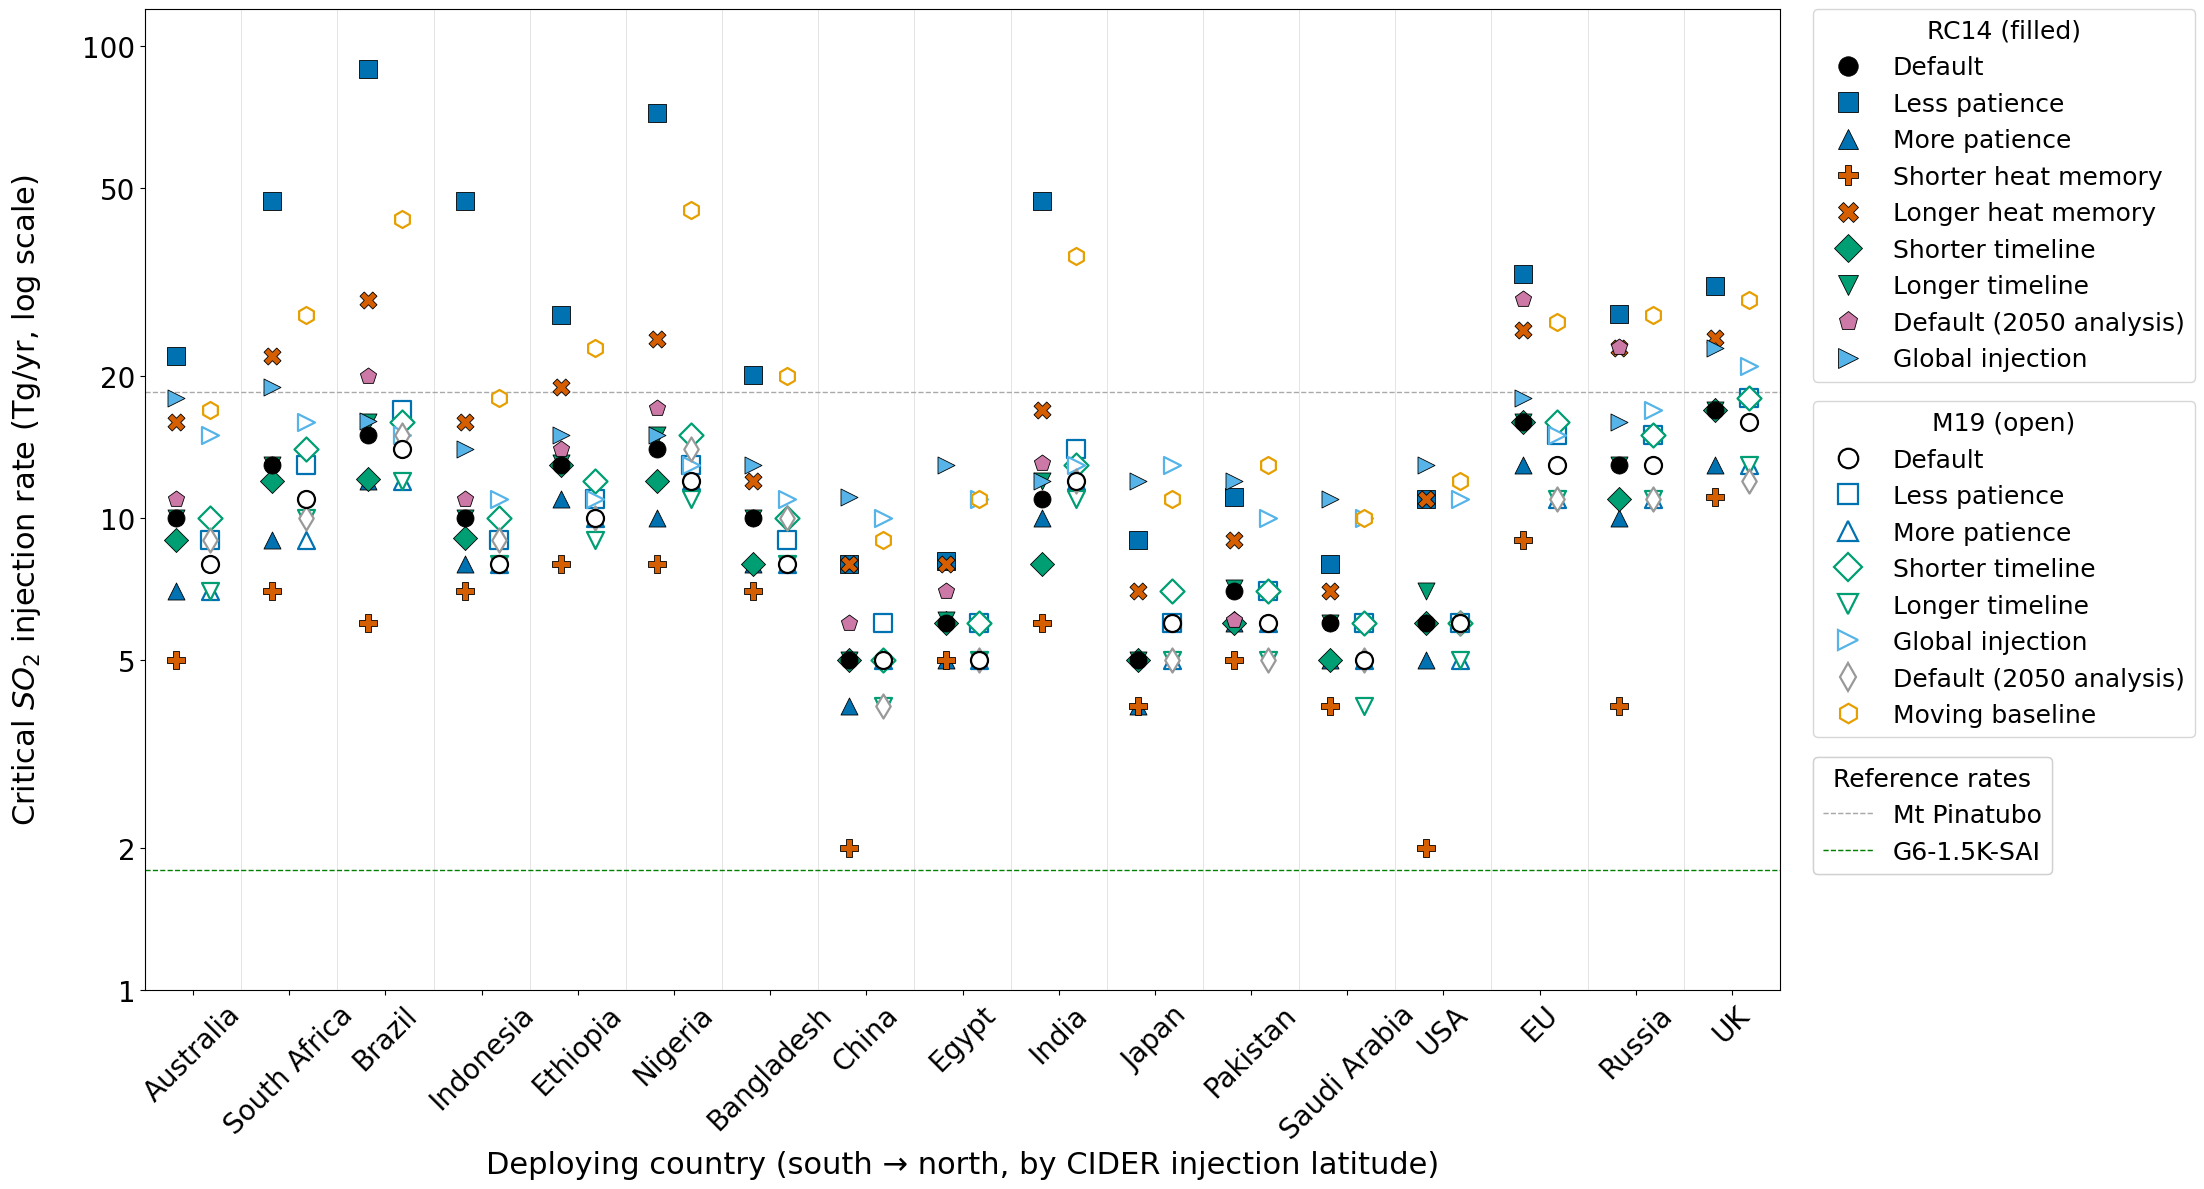

In [30]:
group_spacing = 1.7   # horizontal space between each country's pair of columns
col_offset = 0.3     # half the distance between a country's two columns (RC'14 vs M19)

## Order countries left-to-right by CIDER injection latitude
cider_lat_by_country = {c: float(cider_inj_lats_popweighted.sel(country=c).nearest_cider_lat.values)
                         for c in countries_of_interest}
country_order = sorted(countries_of_interest, key=lambda c: cider_lat_by_country[c])

x_center = {c: i * group_spacing for i, c in enumerate(country_order)}
x_rc  = {c: x_center[c] - col_offset for c in country_order}
x_mem = {c: x_center[c] + col_offset for c in country_order}

## Fixed marker for every (param, level) combination for both models. 
full_marker_map = {("default", None): 'o',
                    ("buffer", 6): 's',
                    ("buffer", 18): '^',
                    ("tau", 6): 'P',
                    ("tau", 18): 'X',
                    ("eval_len", 24): 'D',
                    ("eval_len", 48): 'v',
                    ("k_setting", "country_k_2050"): 'p',   # RC'14 only
                    ("deployment", 2050): 'd',                 # M'19 only
                    ("injection_type", "uniform"): '>',
                    ("moving_baseline", None): 'h'}

shared_marker_map = {k: v for k, v in full_marker_map.items()
                      if k in {("default", None), ("buffer", 6), ("buffer", 18),
                               ("eval_len", 24), ("eval_len", 48), ("injection_type", "uniform"),
                               ("moving_baseline", None), ("deployment", 2050)}}

scenario_order = list(dict.fromkeys(df["scenario"]))
marker_map = {}
for scen in scenario_order:
    sub = df[df["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    marker_map[scen] = full_marker_map[key]   # KeyError if an unexpected (param, level) shows up

mem_scenario_order = list(dict.fromkeys(df_mem["scenario"]))
mem_marker_map = {}
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    mem_marker_map[scen] = shared_marker_map.get(key, 'o')

## Plot "Default" last (on top) in each column 
default_label = scenario_label(default_scenario)
mem_default_label = mem_scenario_label(None, None, is_default=True)
scenario_order = [s for s in scenario_order if s != default_label] + [default_label]
mem_scenario_order = [s for s in mem_scenario_order if s != mem_default_label] + [mem_default_label]

## Okabe-Ito colorblind-safe palette (Okabe & Ito, 2008)
param_colors = {
    "default": "#000000",         # black
    "buffer": "#0072B2",          # blue
    "tau": "#D55E00",             # vermillion
    "eval_len": "#009E73",        # bluish green
    "k_setting": "#CC79A7",       # reddish purple
    "injection_type": "#56B4E9",  # sky blue
    "moving_baseline": "#E69F00", # orange
    "deployment": "#999999",}     # gray


fig, ax = plt.subplots(figsize=(18, 12))

## RC'14 -- filled markers, left column 
for scen in scenario_order:
    sub = df[df["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    ax.scatter(
        [x_rc[c] for c in sub["country"]],
        sub["p90_min_injection"],
        marker=marker_map[scen],
        color=param_colors.get(param_varied, "gray"),
        s=150, edgecolor="k", linewidth=0.6, zorder=3)

## M et al. '19 -- open/hollow markers, right column
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    color = param_colors.get(param_varied, "gray")
    ax.scatter(
        [x_mem[c] for c in sub["country"]],
        sub["min_injection_rate"],
        marker=mem_marker_map[scen],
        facecolor="white",
        edgecolor=color, linewidth=1.6, s=150, zorder=3)

## Faint separators between each country's pair of columns
for i in range(len(country_order) - 1):
    ax.axvline(x_center[country_order[i]] + group_spacing / 2,
               color="gray", linewidth=0.6, linestyle="-", alpha=0.25, zorder=1)

ax.set_xticks(list(x_center.values()))
ax.set_xticklabels([country_short_names[c] for c in country_order], fontsize=20, rotation=45)
ax.set_xlim(-group_spacing / 2, (len(country_order) - 1) * group_spacing + group_spacing / 2)

ax.set_yscale("log")
yticks = [1, 2, 5, 10, 20, 50, 100]
ax.set_yticks(yticks)
ax.set_yticklabels([str(t) for t in yticks], fontsize=20)
ax.minorticks_off()
ax.set_ylim(1, 120)  

ax.set_ylabel("Critical $SO_{2}$ injection rate (Tg/yr, log scale)\n",
              fontsize=22)
# ax.set_title("Sensitivity of minimum $SO_{2}$ injection rate\n", fontsize=24)
ax.set_xlabel('Deploying country (south \u2192 north, by CIDER injection latitude)', fontsize=22)

## ------------------------------------------------------------------
## Manual legends
## ------------------------------------------------------------------
from matplotlib.lines import Line2D

## filled markers, RC'14
rc14_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter heat memory",                  marker='P', color=param_colors["tau"]),
    dict(label="Longer heat memory",                 marker='X', color=param_colors["tau"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Default (2050 analysis)",     marker='p', color=param_colors["k_setting"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"])]

## open/hollow markers for M et al. '19
mem_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"]),
    dict(label="Default (2050 analysis)", marker='d', color=param_colors["deployment"]),
    dict(label="Moving baseline",   marker='h', color=param_colors["moving_baseline"])]

def make_handle(marker, color, filled):
    return Line2D(
        [], [], linestyle="None", marker=marker,
        markersize=14,
        markerfacecolor=color if filled else "white",
        markeredgecolor="k" if filled else color,
        markeredgewidth=0.6 if filled else 1.6)

rc_handles = [make_handle(e["marker"], e["color"], filled=True) for e in rc14_legend_entries]
rc_labels  = [e["label"] for e in rc14_legend_entries]

mem_handles = [make_handle(e["marker"], e["color"], filled=False) for e in mem_legend_entries]
mem_labels  = [e["label"] for e in mem_legend_entries]

## Reference injection rates 
pinatubo_line = ax.axhline(18.5, linewidth=1, linestyle='--', color='darkgrey', label='Mt Pinatubo')
g6_line       = ax.axhline(1.8,  linewidth=1, linestyle='--', color='green',    label='G6-1.5K-SAI')

plt.tight_layout()

## vertically stack legends to the right of the figure
legend_specs = [(rc_handles,  rc_labels,  "RC14 (filled)"),
                (mem_handles, mem_labels, "M19 (open)"),
                ([pinatubo_line, g6_line], ["Mt Pinatubo", "G6-1.5K-SAI"], "Reference rates")]
legend_gap = 0.02    # vertical gap between stacked legends, in axes-fraction units
y_top = 1.0
for handles, labels, title in legend_specs:
    leg = ax.legend(handles, labels, title=title,
                    bbox_to_anchor=(1.02, y_top), loc="upper left", borderaxespad=0,
                    fontsize=18, title_fontsize=18, frameon=True)
    ax.add_artist(leg)       
    leg.set_clip_on(False)   
    fig.canvas.draw()       
    bb = leg.get_window_extent().transformed(ax.transAxes.inverted())
    y_top = bb.y0 - legend_gap

plt.savefig(newpath + f'Sensitivity_test_{model_type}_log_scale.pdf', bbox_inches='tight')
plt.savefig(newpath + f'Sensitivity_test_{model_type}_log_scale.png', bbox_inches='tight')

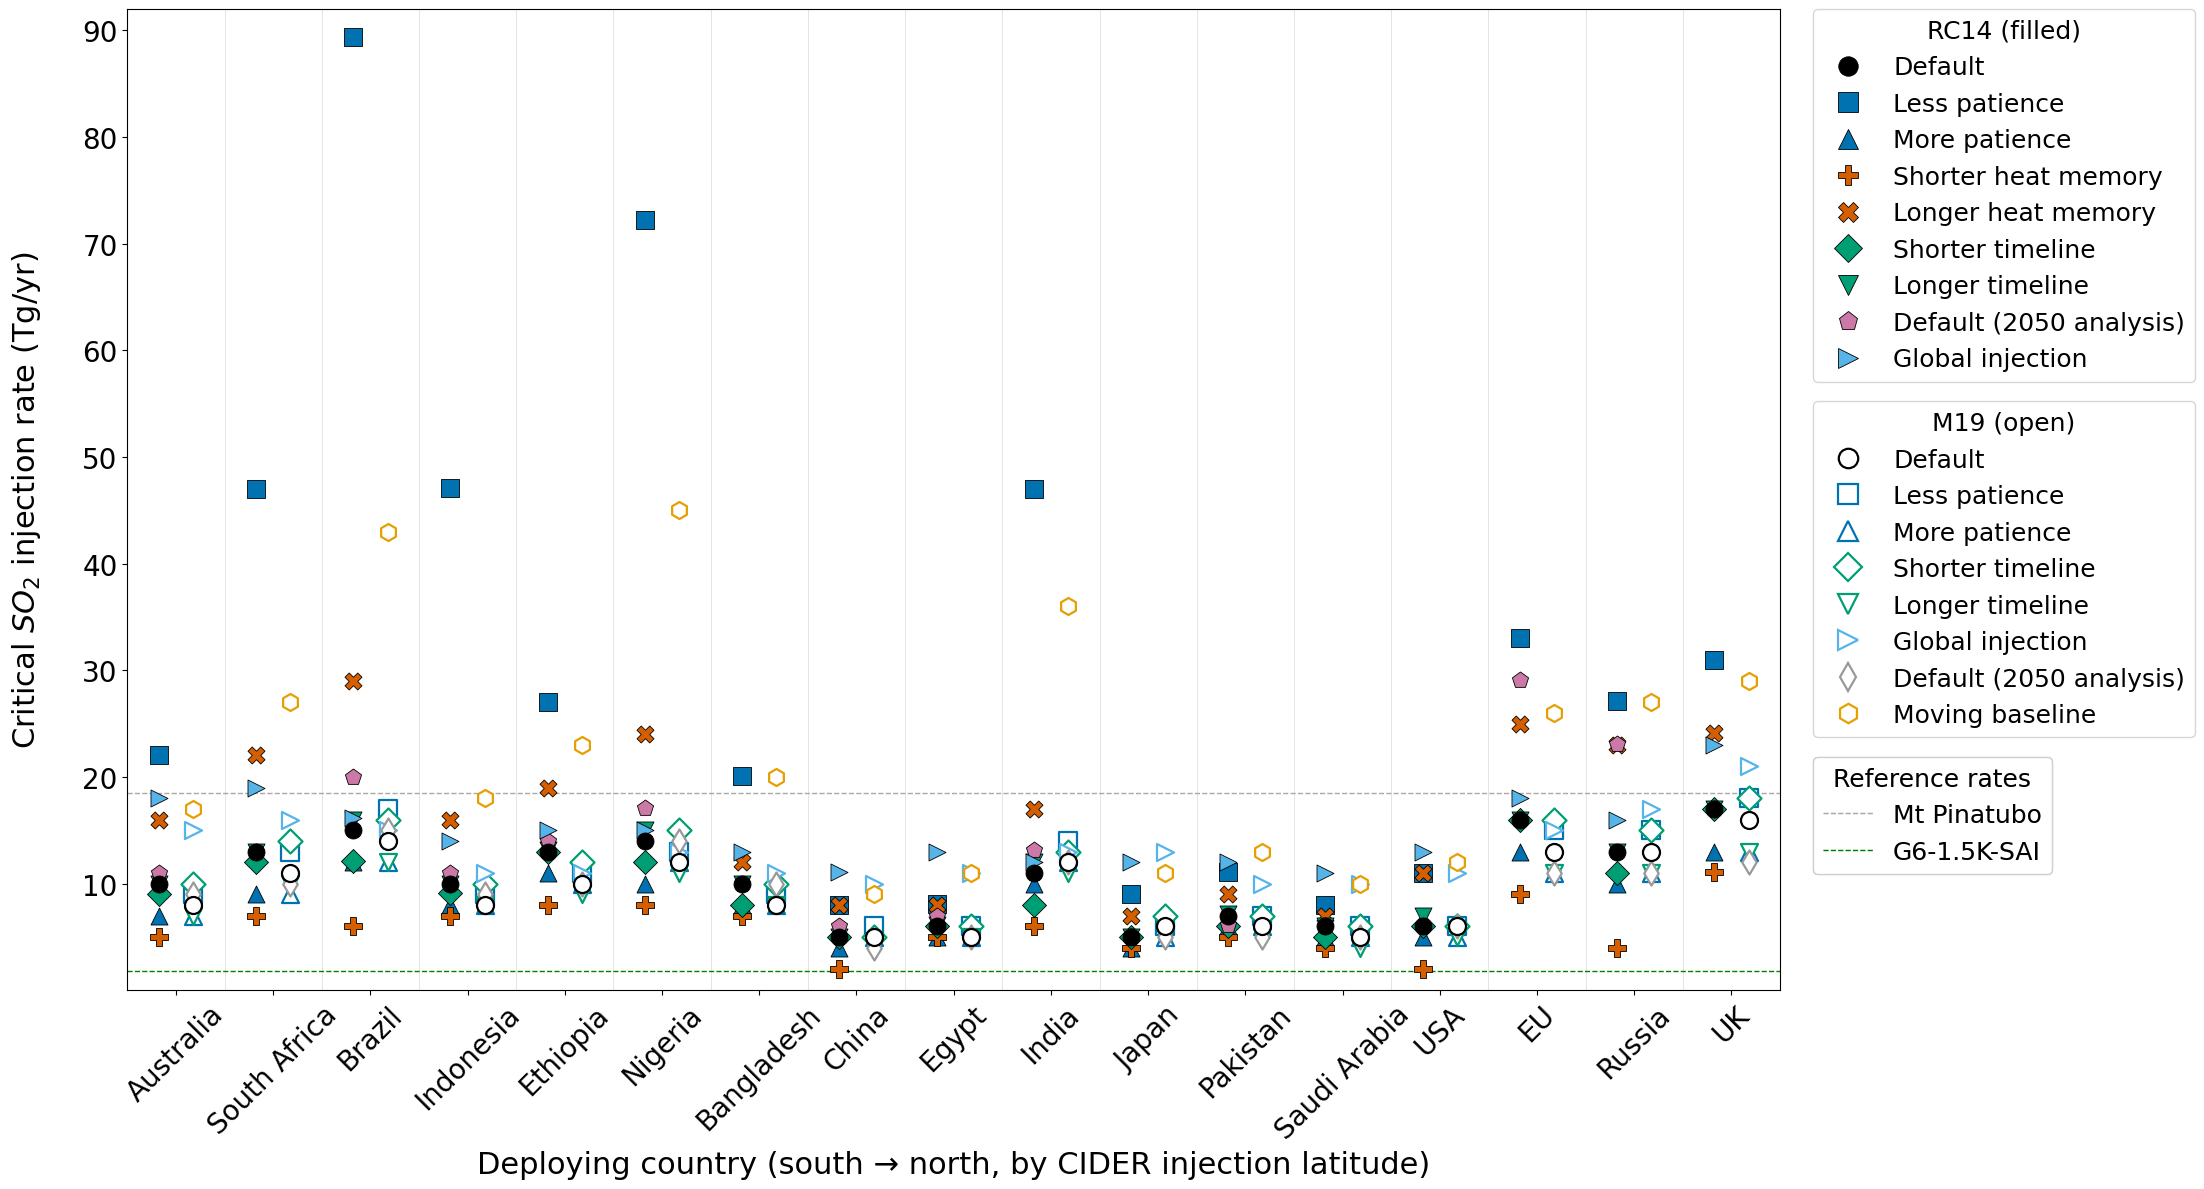

In [28]:
## Linear scale

group_spacing = 1.7   # horizontal space between each country's pair of columns
col_offset = 0.3     # half the distance between a country's two columns (RC'14 vs M19)

## Order countries left-to-right by CIDER injection latitude: furthest south on the far
## left, furthest north on the far right (uses the same values loaded in the cell above).
cider_lat_by_country = {c: float(cider_inj_lats_popweighted.sel(country=c).nearest_cider_lat.values)
                         for c in countries_of_interest}
country_order = sorted(countries_of_interest, key=lambda c: cider_lat_by_country[c])

x_center = {c: i * group_spacing for i, c in enumerate(country_order)}
x_rc  = {c: x_center[c] - col_offset for c in country_order}
x_mem = {c: x_center[c] + col_offset for c in country_order}


## Fixed marker for every (param, level) combination -- both models. This is the single
## source of truth for markers; it does NOT depend on which scenarios actually loaded,
## so a missing results file just means that marker is absent from the plot, never that
## markers shift and desync from the hardcoded legend below.
full_marker_map = {("default", None): 'o',
                    ("buffer", 6): 's',
                    ("buffer", 18): '^',
                    ("tau", 6): 'P',
                    ("tau", 18): 'X',
                    ("eval_len", 24): 'D',
                    ("eval_len", 48): 'v',
                    ("k_setting", "low_k"): '*',
                    ("k_setting", "high_k"): '<',
                    ("k_setting", "country_k_2050"): 'p',   # RC'14 only
                    ("deployment", 2050): 'd',                 # M'19 only
                    ("injection_type", "uniform"): '>',
                    ("moving_baseline", None): 'h'}

shared_marker_map = {k: v for k, v in full_marker_map.items()
                      if k in {("default", None), ("buffer", 6), ("buffer", 18),
                               ("eval_len", 24), ("eval_len", 48), ("injection_type", "uniform"),
                               ("moving_baseline", None), ("deployment", 2050)}}

scenario_order = list(dict.fromkeys(df["scenario"]))
marker_map = {}
for scen in scenario_order:
    sub = df[df["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    marker_map[scen] = full_marker_map[key]   # KeyError if an unexpected (param, level) shows up

mem_scenario_order = list(dict.fromkeys(df_mem["scenario"]))
mem_marker_map = {}
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    mem_marker_map[scen] = shared_marker_map.get(key, 'o')

## Plot "Default" last (on top) in each column so it's never hidden behind a nearby marker
default_label = scenario_label(default_scenario)
mem_default_label = mem_scenario_label(None, None, is_default=True)
scenario_order = [s for s in scenario_order if s != default_label] + [default_label]
mem_scenario_order = [s for s in mem_scenario_order if s != mem_default_label] + [mem_default_label]

## Okabe-Ito colorblind-safe palette (Okabe & Ito, 2008)
param_colors = {
    "default": "#000000",         # black
    "buffer": "#0072B2",          # blue
    "tau": "#D55E00",             # vermillion
    "eval_len": "#009E73",        # bluish green
    "k_setting": "#CC79A7",       # reddish purple
    "injection_type": "#56B4E9",  # sky blue
    "moving_baseline": "#E69F00", # orange
    "deployment": "#999999",}     # gray


fig, ax = plt.subplots(figsize=(18, 12))

## RC'14 -- filled markers, left column of each country pair
for scen in scenario_order:
    sub = df[df["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    ax.scatter(
        [x_rc[c] for c in sub["country"]],
        sub["p90_min_injection"],
        marker=marker_map[scen],
        color=param_colors.get(param_varied, "gray"),
        s=150, edgecolor="k", linewidth=0.6, zorder=3)

## M et al. '19 -- open/hollow markers, right column of each country pair
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    color = param_colors.get(param_varied, "gray")
    ax.scatter(
        [x_mem[c] for c in sub["country"]],
        sub["min_injection_rate"],
        marker=mem_marker_map[scen],
        facecolor="white",
        edgecolor=color, linewidth=1.6, s=150, zorder=3)

## Faint separators between each country's pair of columns
for i in range(len(country_order) - 1):
    ax.axvline(x_center[country_order[i]] + group_spacing / 2,
               color="gray", linewidth=0.6, linestyle="-", alpha=0.25, zorder=1)

ax.set_xticks(list(x_center.values()))
ax.set_xticklabels([country_short_names[c] for c in country_order], fontsize=20, rotation=45)
ax.set_xlim(-group_spacing / 2, (len(country_order) - 1) * group_spacing + group_spacing / 2)
# # ax.grid(axis="y", alpha=0.3, zorder=0)
yticks = [10, 20, 30, 40, 50, 60, 70, 80, 90]
ax.set_yticks(yticks)
ax.set_yticklabels([str(tick) for tick in yticks], fontsize=20)
ax.set_ylim(0, 92)

ax.set_ylabel("Critical $SO_{2}$ injection rate (Tg/yr)\n",
              fontsize=22)
# ax.set_title("Sensitivity of minimum $SO_{2}$ injection rate\n", fontsize=24)
ax.set_xlabel('Deploying country (south \u2192 north, by CIDER injection latitude)', fontsize=22)

## ------------------------------------------------------------------
## Manual legends: edit these two lists directly to control exactly what shows up, in what order, 
## and how it's labeled -- independent of which scenarios happen to be in `df` / `df_mem`. Pull 
## marker/color from the maps above to stay in sync with what's actually plotted, or hardcode
## your own if you want the legend fully decoupled from the data.
## ------------------------------------------------------------------
from matplotlib.lines import Line2D

## filled markers -- one row per legend entry you want to show for RC'14
rc14_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter heat memory",                  marker='P', color=param_colors["tau"]),
    dict(label="Longer heat memory",                 marker='X', color=param_colors["tau"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Default (2050 analysis)",     marker='p', color=param_colors["k_setting"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"])]

## open/hollow markers -- one row per legend entry you want to show for M et al. '19
mem_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"]),
    dict(label="Default (2050 analysis)", marker='d', color=param_colors["deployment"]),
    dict(label="Moving baseline",   marker='h', color=param_colors["moving_baseline"])]

def make_handle(marker, color, filled):
    return Line2D(
        [], [], linestyle="None", marker=marker,
        markersize=14,
        markerfacecolor=color if filled else "white",
        markeredgecolor="k" if filled else color,
        markeredgewidth=0.6 if filled else 1.6)

rc_handles = [make_handle(e["marker"], e["color"], filled=True) for e in rc14_legend_entries]
rc_labels  = [e["label"] for e in rc14_legend_entries]

mem_handles = [make_handle(e["marker"], e["color"], filled=False) for e in mem_legend_entries]
mem_labels  = [e["label"] for e in mem_legend_entries]

## Reference injection rates (drawn once; handles are kept for their own legend)
pinatubo_line = ax.axhline(18.5, linewidth=1, linestyle='--', color='darkgrey', label='Mt Pinatubo')
g6_line       = ax.axhline(1.8,  linewidth=1, linestyle='--', color='green',    label='G6-1.5K-SAI')

## Lay out the axes first, THEN add legends outside, so tight_layout doesn't shrink the plot
## to make room for them. savefig(bbox_inches="tight") below still includes the legends.
plt.tight_layout()

## Stack the three legends vertically in the margin to the right of the plot. Each legend is
## anchored just below the previous one, using its rendered height, so spacing stays correct
## even if you add/remove entries or change font sizes.
legend_specs = [(rc_handles,  rc_labels,  "RC14 (filled)"),
                (mem_handles, mem_labels, "M19 (open)"),
                ([pinatubo_line, g6_line], ["Mt Pinatubo", "G6-1.5K-SAI"], "Reference rates")]
legend_gap = 0.02    # vertical gap between stacked legends, in axes-fraction units
y_top = 1.0
for handles, labels, title in legend_specs:
    leg = ax.legend(handles, labels, title=title,
                    bbox_to_anchor=(1.02, y_top), loc="upper left", borderaxespad=0,
                    fontsize=18, title_fontsize=18, frameon=True)
    ax.add_artist(leg)       # so the next ax.legend() call doesn't replace this one
    leg.set_clip_on(False)   # add_artist clips to the axes box, which hides legends placed outside it
    fig.canvas.draw()        # needed to get the legend's true rendered size
    bb = leg.get_window_extent().transformed(ax.transAxes.inverted())
    y_top = bb.y0 - legend_gap

plt.savefig(newpath + f'Sensitivity_test_{model_type}.pdf', bbox_inches='tight')
plt.savefig(newpath + f'Sensitivity_test_{model_type}.png', bbox_inches='tight')